# Site analysis for Kuva Space (Hyperfield): what imagery exists at my sites

Kuva Space hyperspectral products (Hyperfield-1A / 1B) from the **Kuva Sense Products API** (`kuva` provider:
collections = processing levels L1B, L1C, L2A; one acquisition = one capture, `raw_product_landing_id`, across
its levels) and CSDA's `kuvaspace` STAC collection. The Kuva account has search access only (no downloads), so
this notebook stops at the variation plots. Same layout as `multistac_site_analysis_satellogic.ipynb`.

Searches every catalog you can access (CSDA STAC, NASA CMR's CSDA archive, vendor APIs) at a set of
sites, then shows **what** exists, **where** and **when**, how the acquisitions **vary** (cloud, GSD,
view and sun geometry), and **downloads** the selection from CSDA STAC or Earthdata with your
credentials.

| Step | Output |
|---|---|
| 1. Catalog overview | first/last acquisition and timeline per collection (catalog-wide) |
| 2. Search | one table: common columns (provider, affiliation, constellation, sensor, angles, ...) + all vendor properties |
| 3. What and where | counts per site and sensor, monthly heatmaps |
| 4. Variation | distributions by constellation, skyplots per site |
| 5. Select and download | filter, choose assets, download, manifest |

Library: `lib/multistac.py` (search), `lib/multistac_plots.py`, `lib/multistac_download.py`.
Profiles and vocabularies: `lib/stac_providers.yaml`, `lib/sensor_catalog.yaml`.

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import matplotlib.pyplot as plt
import multistac, multistac_plots, multistac_download
for m in (multistac, multistac_plots, multistac_download):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## Parameters

In [2]:
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_NAMES = None #['San Francisco', 'Railroad Valley','Belo Horizonte']   # None = all sites in the file
SITE_FILTERS = {'Remote Sensing Domain': 'Optical'}   # {field: value} on the sites file; str = contains (case-insensitive), list = exact values; None = no filter

START, END = '2020-01-01', '2026-12-31'   # Kuva Sense products start 2025-01-24; earlier years confirm there is nothing before
MONTHS = None              # e.g. [6, 7, 8]
CLOUD_COVER_MAX = 20    # percent; Kuva sends it with the request; None keeps SAR/DEM/no-cloud-cover collections

CSDA_INCLUDE = ['kuvaspace']           # [] = do not search CSDA at all
CSDA_EXCLUDE = []
EXTRA_PROVIDERS = {
    'kuva': None,    # Kuva Sense Products API: L1B, L1C, L2A (all by default); e.g. ['L2A'] for one level
}

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac'
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/site_analysis'

In [3]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD, filters=SITE_FILTERS)
if SITE_NAMES:
    sites = sites[sites.site_name.isin(SITE_NAMES)]
print(len(sites), 'sites')
#sites.explore(tooltip='site_name') if len(sites) < 300 else sites.plot()

58 sites


In [4]:
# CSDA STAC collections: only CSDA_INCLUDE (if set), minus CSDA_EXCLUDE
csda_collections = multistac.collections('csda')
CSDA_IDS = [c for c in csda_collections['id']
            if (CSDA_INCLUDE is None or c in CSDA_INCLUDE) and c not in CSDA_EXCLUDE]
missing = set(CSDA_INCLUDE or []) - set(csda_collections['id'])
if missing:
    print('Not in CSDA STAC (check spelling):', sorted(missing))
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))

PROVIDERS = {'csda': CSDA_IDS, **EXTRA_PROVIDERS}
multistac.list_providers()[['provider', 'display_name', 'api', 'enabled']]

1 of 27 CSDA STAC collections: kuvaspace


,provider,display_name,api,enabled
0,csda,CSDA STAC,stac,True
1,satellogic,Satellogic,stac,True
2,csda-cmr,Earthdata CMR – CSDA,cmr,True
3,hydrosat,Hydrosat,stac,True
4,vantor,Vantor,stac,True
5,kuva,Kuva Space,kuva_products,True


## 1. Catalog overview
Catalog-wide (not just your sites). Collections whose catalog reports no counts show their date range as a band.

No catalog counts from this API (use res.by_month()): csda/kuvaspace


,provider,collection,title,first,last,total,dates_from,in_window
0,csda,kuvaspace,Kuvaspace,NaT,NaT,n/a,collection extent,<NA>
1,kuva,L1B,processing level L1B,2025-01-24,2026-11-09,"2,211",items,True
2,kuva,L1C,processing level L1C,2025-01-24,2026-11-09,"1,857",items,True
3,kuva,L2A,processing level L2A,2025-01-24,2026-11-09,"1,851",items,True


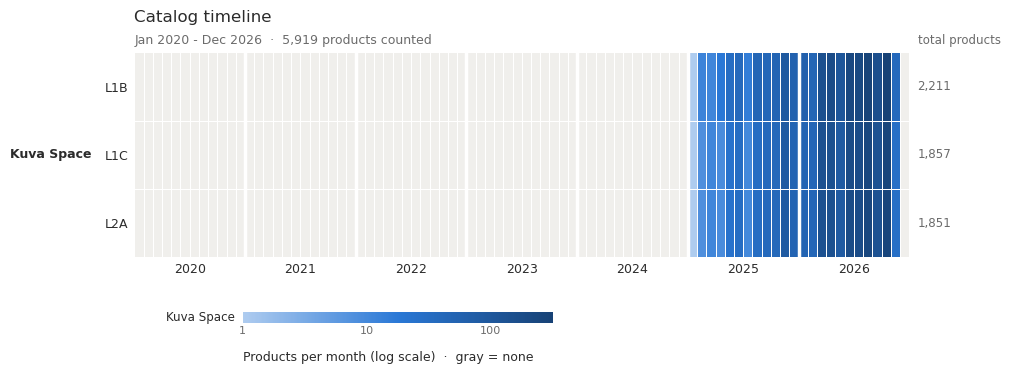

In [5]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');
catalog_overview

## 2. Search the sites

In [6]:
%%time
res = multistac.search(sites, START, END, PROVIDERS, months=MONTHS,
                       cloud_cover_max=CLOUD_COVER_MAX, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']

searches: 100%|██████████| 232/232 [00:00<00:00, 301.50it/s]


SearchResult(2387 rows, 1816 unique items, 0 failed tasks)
CPU times: user 1.23 s, sys: 193 ms, total: 1.42 s
Wall time: 2.08 s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


In [7]:
res.summary()

,provider,collection,processing_level,rows,products,acquisitions,sites
0,kuva,L1B,L1B,812,613,613,22
1,kuva,L1C,L1C,788,602,602,22
2,kuva,L2A,L2A,787,601,601,22


## 3. What do we have, and where?

**These counts are products, not acquisitions.** Each row of `res.gdf` is one catalog item, i.e. one *product*, and one acquisition (one satellite collect) is often delivered as several products:

- **Spectral products:** the panchromatic, multispectral and pansharpened products of one collect are separate items, e.g. Legion `P2AS` / `M2AS` / `S3DS`, Airbus `P` / `MS` / `PMS`, Maxar `P1BS` / `M1BS` in CMR. The `spectral_mode` column says which.
- **Processing levels:** the same collect at several levels (Legion `LV1B` / `LV2A` / `LV3D`, Satellogic `L1B` / `L1D_SR`).
- **File formats:** BlackSky delivers each collect as up to four items (GeoTIFF and NITF, ortho and non-ortho).

`acquisition_id` groups the products of one collect, so count `acquisition_id.nunique()` to answer "how many times was this site imaged?", and `id.nunique()` for "how many products are there?". The table below shows both.

**The plots take `count='products'` or `count='acquisitions'`** (`res.by_month(..., count=...)`, `plot_density_maps(..., count=...)`, `plot_distributions(..., count=...)`), and every title, axis and colorbar says which one is counted. Skyplots default to acquisitions (the products of one collect share its geometry).

Overlapping sites (e.g. WLEF and its skycams) also share products: count by `site_group` to count each product once per group (see the parameters section).


In [8]:
print(res.gdf.columns.to_list())

['provider', 'affiliation', 'constellation', 'sensor', 'collection', 'id', 'datetime', 'site_name', 'site_group', 'cloud_cover', 'processing_level', 'product_type', 'spectral_mode', 'acquisition_id', 'platform', 'instrument', 'gsd', 'off_nadir', 'incidence_angle', 'view_azimuth', 'sun_elevation', 'sun_azimuth', 'sat_azimuth', 'sat_elevation', 'sat_elevation_source', 'vendor_item_id', 'in_csda', 'stac_self_href', 'eo:cloud_cover', 'processing:level', 'kuva:product_id', 'kuva:raw_product_landing_id', 'kuva:satellite_short_name', 'kuva:area_coverage_percentage', 'kuva:available_processing_levels', 'kuva:qc_passed', 'geometry']


In [9]:
# Products vs acquisitions per constellation, and the product mix (spectral_mode x processing level)
gdf = res.gdf.drop_duplicates(['provider', 'id'])

counts = gdf.groupby(['affiliation', 'constellation']).agg(products=('id', 'size'), acquisitions=('acquisition_id', 'nunique'),
                                                        sites=('site_name', 'nunique'))
counts['products_per_acquisition'] = (counts.products / counts.acquisitions).round(2)
display(counts.sort_values('products', ascending=False))
gdf.groupby(['constellation', 'spectral_mode', 'processing_level'], dropna=False).size().unstack('processing_level', fill_value=0)


,,products,acquisitions,sites,products_per_acquisition
affiliation,constellation,,,,
Kuva Space,Hyperfield,1816,622,18,2.92


,processing_level,L1B,L1C,L2A
constellation,spectral_mode,,,
Hyperfield,hyperspectral,613,602,601


In [10]:
gdf.tail()

,provider,affiliation,constellation,sensor,collection,id,datetime,site_name,site_group,cloud_cover,processing_level,product_type,spectral_mode,acquisition_id,platform,instrument,gsd,off_nadir,incidence_angle,view_azimuth,sun_elevation,sun_azimuth,sat_azimuth,sat_elevation,sat_elevation_source,vendor_item_id,in_csda,stac_self_href,eo:cloud_cover,processing:level,kuva:product_id,kuva:raw_product_landing_id,kuva:satellite_short_name,kuva:area_coverage_percentage,kuva:available_processing_levels,kuva:qc_passed,geometry
2382,kuva,Kuva Space,Hyperfield,HF-1A,L1C,38e5ec54-5670-4bfe-8416-0c5a75534a07,2026-10-21 03:20:49.702360+00:00,Suramadu Bridge,Suramadu Bridge,1.088903,L1C,L1C,hyperspectral,1d7af421-2ae4-438a-a1e7-ed6d72d33d02,Hyperfield-1A,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,38e5ec54-5670-4bfe-8416-0c5a75534a07,<NA>,None,1.088903,L1C,38e5ec54-5670-4bfe-8416-0c5a75534a07,1d7af421-2ae4-438a-a1e7-ed6d72d33d02,HF-1A,100.0,[L1C],True,"POLYGON ((112.96661 -7.44015, 112.96752 -7.440..."
2383,kuva,Kuva Space,Hyperfield,HF-1A,L2A,202ac279-4315-46a0-a34d-aec6ea712d54,2026-10-21 03:20:49.702360+00:00,Suramadu Bridge,Suramadu Bridge,1.088903,L2A,L2A,hyperspectral,1d7af421-2ae4-438a-a1e7-ed6d72d33d02,Hyperfield-1A,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,202ac279-4315-46a0-a34d-aec6ea712d54,<NA>,None,1.088903,L2A,202ac279-4315-46a0-a34d-aec6ea712d54,1d7af421-2ae4-438a-a1e7-ed6d72d33d02,HF-1A,100.0,[L2A],True,"POLYGON ((112.96661 -7.44015, 112.96752 -7.440..."
2384,kuva,Kuva Space,Hyperfield,HF-1A,L1B,81c4e2eb-cb03-4ce5-af8b-4ffcbb0847a5,2026-10-21 03:20:54.707654+00:00,Suramadu Bridge,Suramadu Bridge,1.123376,L1B,L1B,hyperspectral,281e4aee-1dfe-444a-afef-49fe47005f0c,Hyperfield-1A,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,81c4e2eb-cb03-4ce5-af8b-4ffcbb0847a5,<NA>,None,1.123376,L1B,81c4e2eb-cb03-4ce5-af8b-4ffcbb0847a5,281e4aee-1dfe-444a-afef-49fe47005f0c,HF-1A,100.0,[L1B],True,"POLYGON ((112.59601 -6.96717, 112.54485 -7.387..."
2385,kuva,Kuva Space,Hyperfield,HF-1A,L1C,80ce7212-b193-4ab3-97f2-bde0926890bb,2026-10-21 03:20:54.707654+00:00,Suramadu Bridge,Suramadu Bridge,1.131338,L1C,L1C,hyperspectral,281e4aee-1dfe-444a-afef-49fe47005f0c,Hyperfield-1A,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,80ce7212-b193-4ab3-97f2-bde0926890bb,<NA>,None,1.131338,L1C,80ce7212-b193-4ab3-97f2-bde0926890bb,281e4aee-1dfe-444a-afef-49fe47005f0c,HF-1A,100.0,[L1C],True,"POLYGON ((112.96799 -7.44480, 112.96889 -7.444..."
2386,kuva,Kuva Space,Hyperfield,HF-1A,L2A,dce78079-3893-432d-bc02-925b148be78e,2026-10-21 03:20:54.707654+00:00,Suramadu Bridge,Suramadu Bridge,1.131338,L2A,L2A,hyperspectral,281e4aee-1dfe-444a-afef-49fe47005f0c,Hyperfield-1A,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,dce78079-3893-432d-bc02-925b148be78e,<NA>,None,1.131338,L2A,dce78079-3893-432d-bc02-925b148be78e,281e4aee-1dfe-444a-afef-49fe47005f0c,HF-1A,100.0,[L2A],True,"POLYGON ((112.96799 -7.44480, 112.96889 -7.444..."


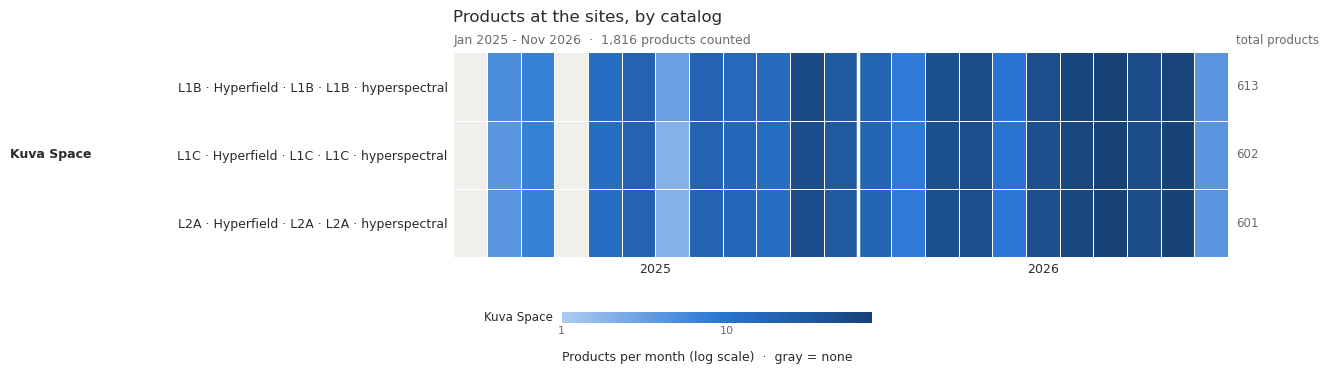

In [11]:
multistac_plots.plot_month_heatmap(res.by_month(['provider', 'collection','constellation','product_type','processing_level','spectral_mode'], count='products'), color_by='provider',
                                   title='Products at the sites, by catalog');

Kuva Sense: 1816 products from 622 acquisitions at 22 sites


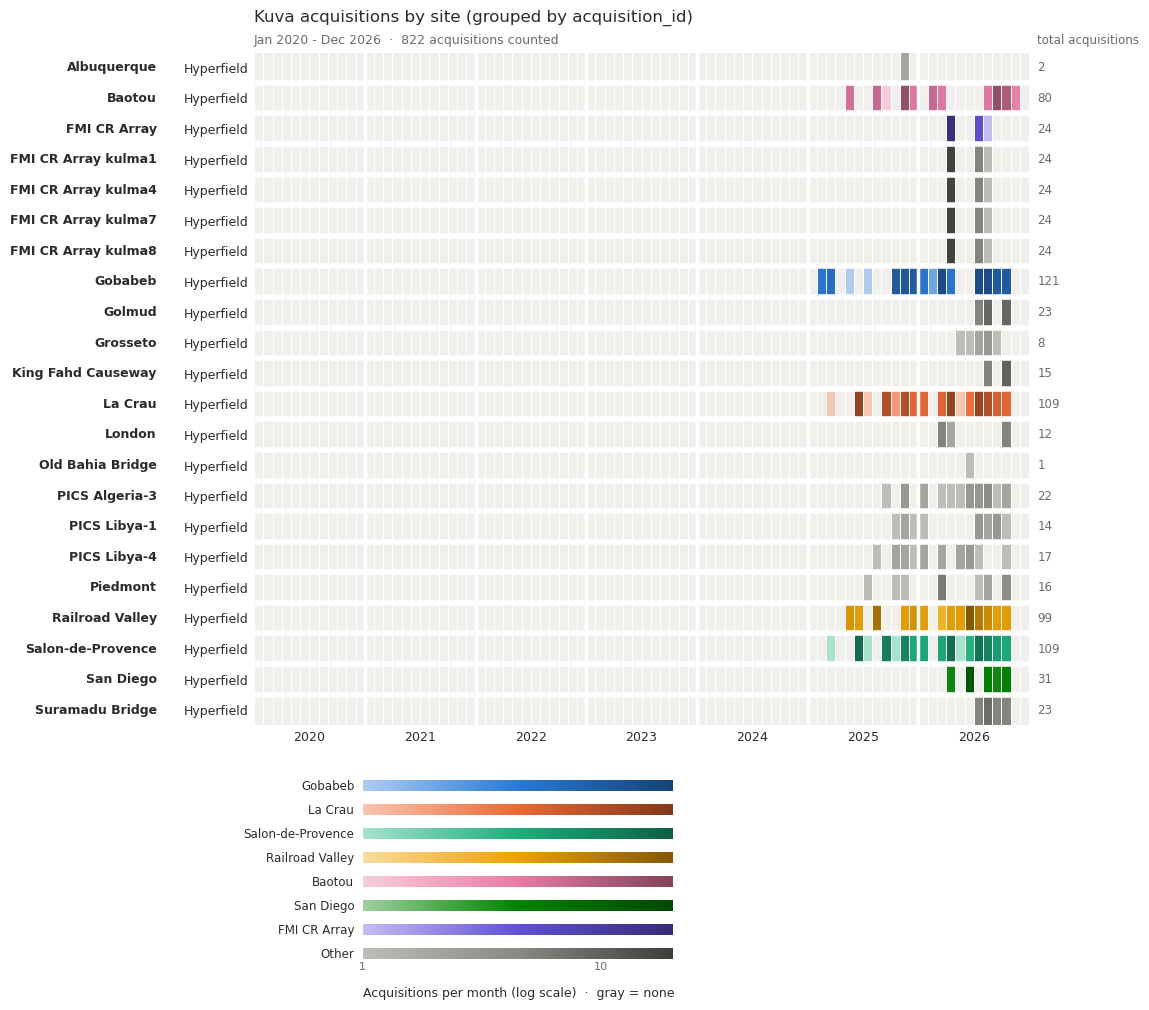

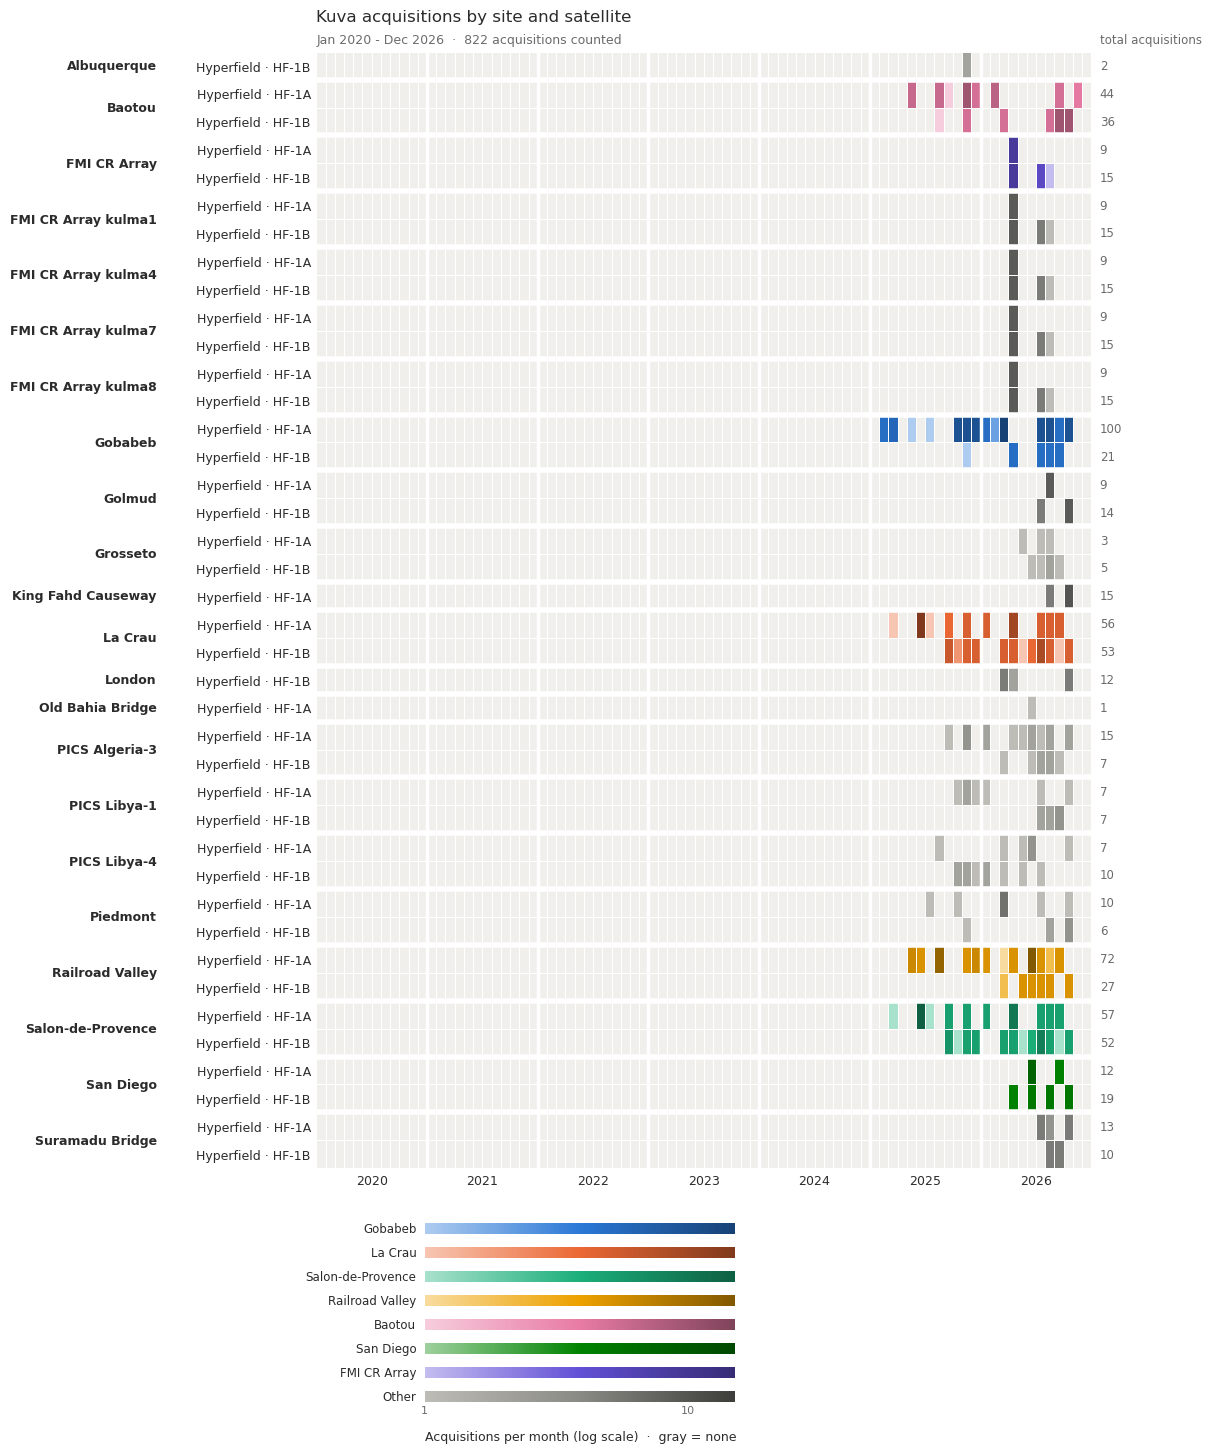

In [12]:
# Kuva Sense products only, counted by acquisition: the L1B / L1C / L2A products of one capture
# (one acquisition_id = raw_product_landing_id) count once. BY sets the rows.
BY = ['site_name', 'constellation', 'sensor']
# kv: one row per product (for maps); kv_sites keeps a row per site an item falls on (res.gdf), so per-site counts
# don't lose a capture that covers two nearby sites
kv = gdf[gdf.provider == 'kuva']
kv_sites = res.gdf[res.gdf.provider == 'kuva']
print(f"Kuva Sense: {kv.id.nunique()} products from {kv.acquisition_id.nunique()} acquisitions at {kv_sites.site_name.nunique()} sites")
multistac_plots.plot_month_heatmap(multistac.month_table(kv_sites, BY[0:2], count='acquisitions'), color_by='site_name', max_rows=None,
                                   start=START[:7], end=END[:7], title='Kuva acquisitions by site (grouped by acquisition_id)');
multistac_plots.plot_month_heatmap(multistac.month_table(kv_sites, BY, count='acquisitions'), color_by='site_name', max_rows=None,
                                   start=START[:7], end=END[:7], title='Kuva acquisitions by site and satellite');

In [13]:
# Acquisitions per site and satellite, and how many of them have each processing level
display(kv_sites.groupby(['site_name', 'sensor'])['acquisition_id'].nunique().unstack('sensor', fill_value=0))
kv_sites.groupby(['site_name', 'processing_level'])['acquisition_id'].nunique().unstack('processing_level', fill_value=0)

sensor,HF-1A,HF-1B
site_name,,
Albuquerque,0,2
Baotou,44,36
FMI CR Array,9,15
FMI CR Array kulma1,9,15
FMI CR Array kulma4,9,15
FMI CR Array kulma7,9,15
FMI CR Array kulma8,9,15
Gobabeb,100,21
Golmud,9,14


processing_level,L1B,L1C,L2A
site_name,,,
Albuquerque,2,2,2
Baotou,78,79,79
FMI CR Array,24,22,22
FMI CR Array kulma1,24,22,22
FMI CR Array kulma4,24,22,22
FMI CR Array kulma7,24,22,22
FMI CR Array kulma8,24,22,22
Gobabeb,121,120,120
Golmud,23,23,23


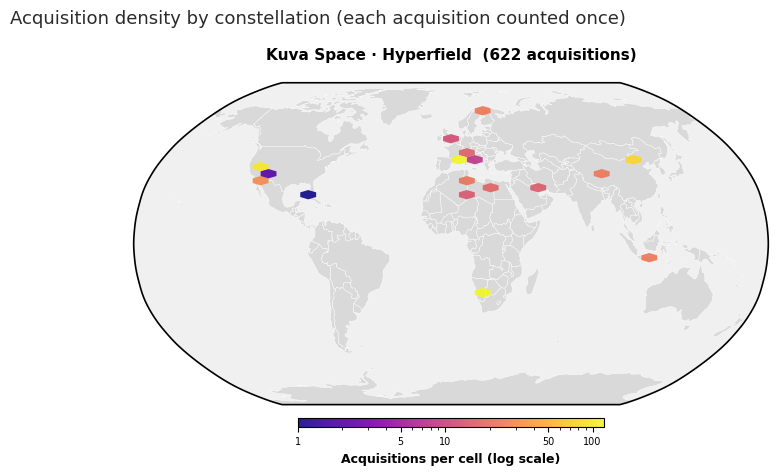

In [14]:
multistac_plots.plot_density_maps(kv, facet_by=['affiliation','constellation'], max_facets=30, gridsize=40,
                                  count='acquisitions', title='Acquisition density by constellation (each acquisition counted once)');

## 4. Inherent variation: cloud, resolution, view and sun geometry

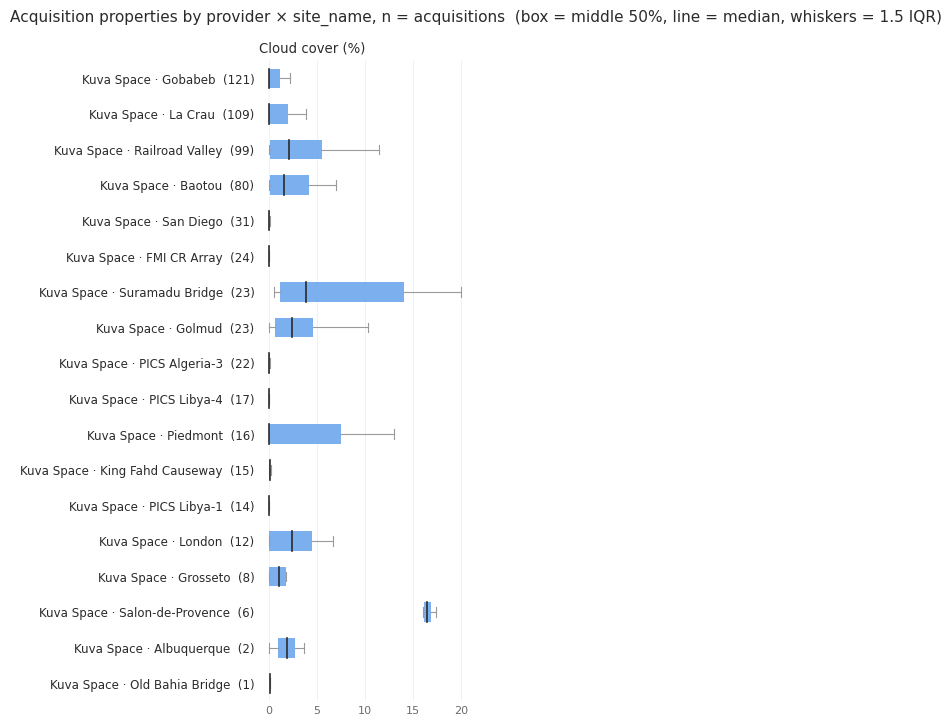

In [15]:
# Kuva Sense products carry cloud cover only (no GSD or view / sun angles); CSDA kuvaspace items may carry more
multistac_plots.plot_distributions(gdf, count='acquisitions', by=['provider', 'site_name']);

In [16]:
# Satellite and sun positions as seen from each site, one dot per acquisition (satellite colored by sensor).
# Rows without azimuths (all Kuva Sense products) are left out; sat_elevation_source says when elevation is estimated.
if gdf[['sat_azimuth', 'sun_azimuth']].notna().all(axis=1).any():
    multistac_plots.plot_skyplot(gdf, facet_by=['constellation','site_group'], color_by='sensor', panel_size=3);
else:
    print('No rows with satellite and sun azimuths: no skyplot')

No rows with satellite and sun azimuths: no skyplot


## Publish to the dashboard

Updates this vendor's tab in `html/archive_first_look.html`, the page for the SMEs: good acquisitions by site and sensor, with the limits set on the page. It runs its own search with no cloud limit so the SMEs can change them, and leaves the results above alone. Commit and push the page and `html/archive_first_look_data/` to publish.

In [17]:
import archive_dashboard
importlib.reload(archive_dashboard)
dash = multistac.search(sites, START, END, PROVIDERS)   # no cloud limit, no cache
print(dash)
archive_dashboard.publish('kuva', dash.gdf, sites, SITES, SITE_NAME_FIELD, START, END, dash.log)

searches: 100%|██████████| 232/232 [00:23<00:00,  9.84it/s]


SearchResult(2661 rows, 2011 unique items, 0 failed tasks)
Kuva Space Hyperfield: 1002 acquisition-site rows, 2011 catalog items, 58 sites
/panfs/ccds02/home/pmontesa/code/csda_summaries/html/archive_first_look.html


PosixPath('/panfs/ccds02/home/pmontesa/code/csda_summaries/html/archive_first_look.html')